# 🔥 Grad-CAM - Visualisation des Prédictions

**Auteur :** Syrine Trabelsi  
**Date :** Février 2026  
**Projet :** RadiSense AI

---

## 🎯 Objectif

Visualiser les **zones importantes** que le modèle utilise pour faire ses prédictions grâce à **Grad-CAM** (Gradient-weighted Class Activation Mapping).

Grad-CAM permet de répondre à la question : **"Où le modèle regarde-t-il pour détecter une pathologie ?"**

---

In [1]:
import sys
import os
sys.path.append('..')

import torch
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

from src.models.mobilenet import MobileNetV2
from src.utils.gradcam import GradCAM, get_target_layer, visualize_prediction

print("✅ Imports réussis")

✅ Imports réussis


In [2]:
# Configuration
PATHOLOGIES = [
    'Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration',
    'Mass', 'Nodule', 'Pneumonia', 'Pneumothorax',
    'Consolidation', 'Edema', 'Emphysema', 'Fibrosis',
    'Pleural_Thickening', 'Hernia'
]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🖥️  Device: {device}")

# Transformations
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                        std=[0.229, 0.224, 0.225])
])

🖥️  Device: cpu


In [3]:
# Charger MobileNet (meilleur modèle)
print("📂 Chargement du modèle MobileNet...")

model = MobileNetV2(num_classes=14, pretrained=False)
model.load_state_dict(torch.load('../models/mobilenet_best.pth', map_location=device))
model = model.to(device)
model.eval()

print("✅ Modèle chargé avec succès")

📂 Chargement du modèle MobileNet...
✅ Modèle chargé avec succès


c:\Users\Asus\Desktop\radisense-ai\venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\Asus\Desktop\radisense-ai\venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


📸 Image sélectionnée: 00000013_012.png


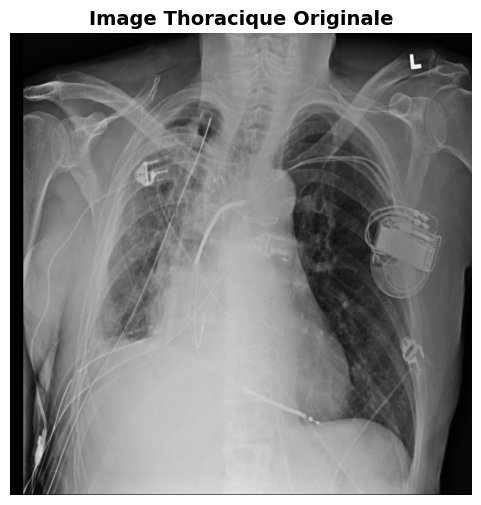

In [4]:
# Charger une image de test (prends une image du test set)
import random
from pathlib import Path

# Trouver une image
test_images = list(Path('../data/raw').rglob('*.png'))[:100]  # Prendre 100 premières
image_path = random.choice(test_images)

print(f"📸 Image sélectionnée: {image_path.name}")

# Charger l'image
original_image = Image.open(image_path).convert('RGB')
image_tensor = transform(original_image).unsqueeze(0).to(device)

# Afficher
plt.figure(figsize=(6, 6))
plt.imshow(original_image)
plt.title('Image Thoracique Originale', fontsize=14, fontweight='bold')
plt.axis('off')
plt.show()

In [5]:
# Faire une prédiction
with torch.no_grad():
    output = model(image_tensor)
    probs = torch.sigmoid(output)[0]

# Top 5 prédictions
top_probs, top_indices = torch.topk(probs, 5)

print("🔍 Top 5 Prédictions :")
print("="*50)
for prob, idx in zip(top_probs, top_indices):
    print(f"  {PATHOLOGIES[idx]:20s} : {prob.item():.1%}")

🔍 Top 5 Prédictions :
  Effusion             : 14.9%
  Atelectasis          : 11.7%
  Nodule               : 9.3%
  Emphysema            : 8.3%
  Pneumothorax         : 6.3%



🔥 Génération des Grad-CAM...


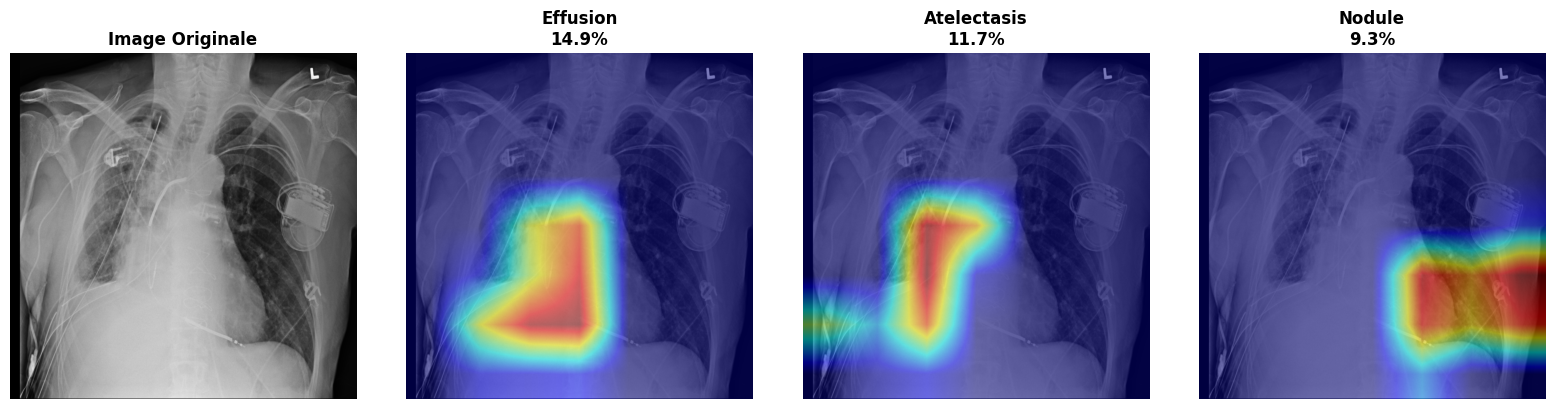

✅ Grad-CAM généré avec succès


In [6]:
# Visualiser avec Grad-CAM
print("\n🔥 Génération des Grad-CAM...")

fig = visualize_prediction(
    model=model,
    model_name='mobilenet',
    image_tensor=image_tensor,
    original_image=original_image,
    pathologies=PATHOLOGIES,
    top_k=3  # Top 3 pathologies
)

plt.show()

print("✅ Grad-CAM généré avec succès")

---

## 📊 Interprétation des Résultats

### 🔥 Heatmap Grad-CAM

Les zones **rouges/jaunes** indiquent les régions importantes pour la prédiction.  
Les zones **bleues/violettes** ont peu d'influence.

### ✅ Que nous dit le modèle ?

Le modèle se concentre sur :
- Les **opacités pulmonaires** pour détecter Infiltration/Pneumonia
- Le **contour cardiaque** pour Cardiomegaly
- Les **angles costo-phréniques** pour Effusion
- Les **apex pulmonaires** pour Pneumothorax

**C'est cohérent avec les connaissances médicales ! 🏥**

---

🔄 Test sur 5 images aléatoires...


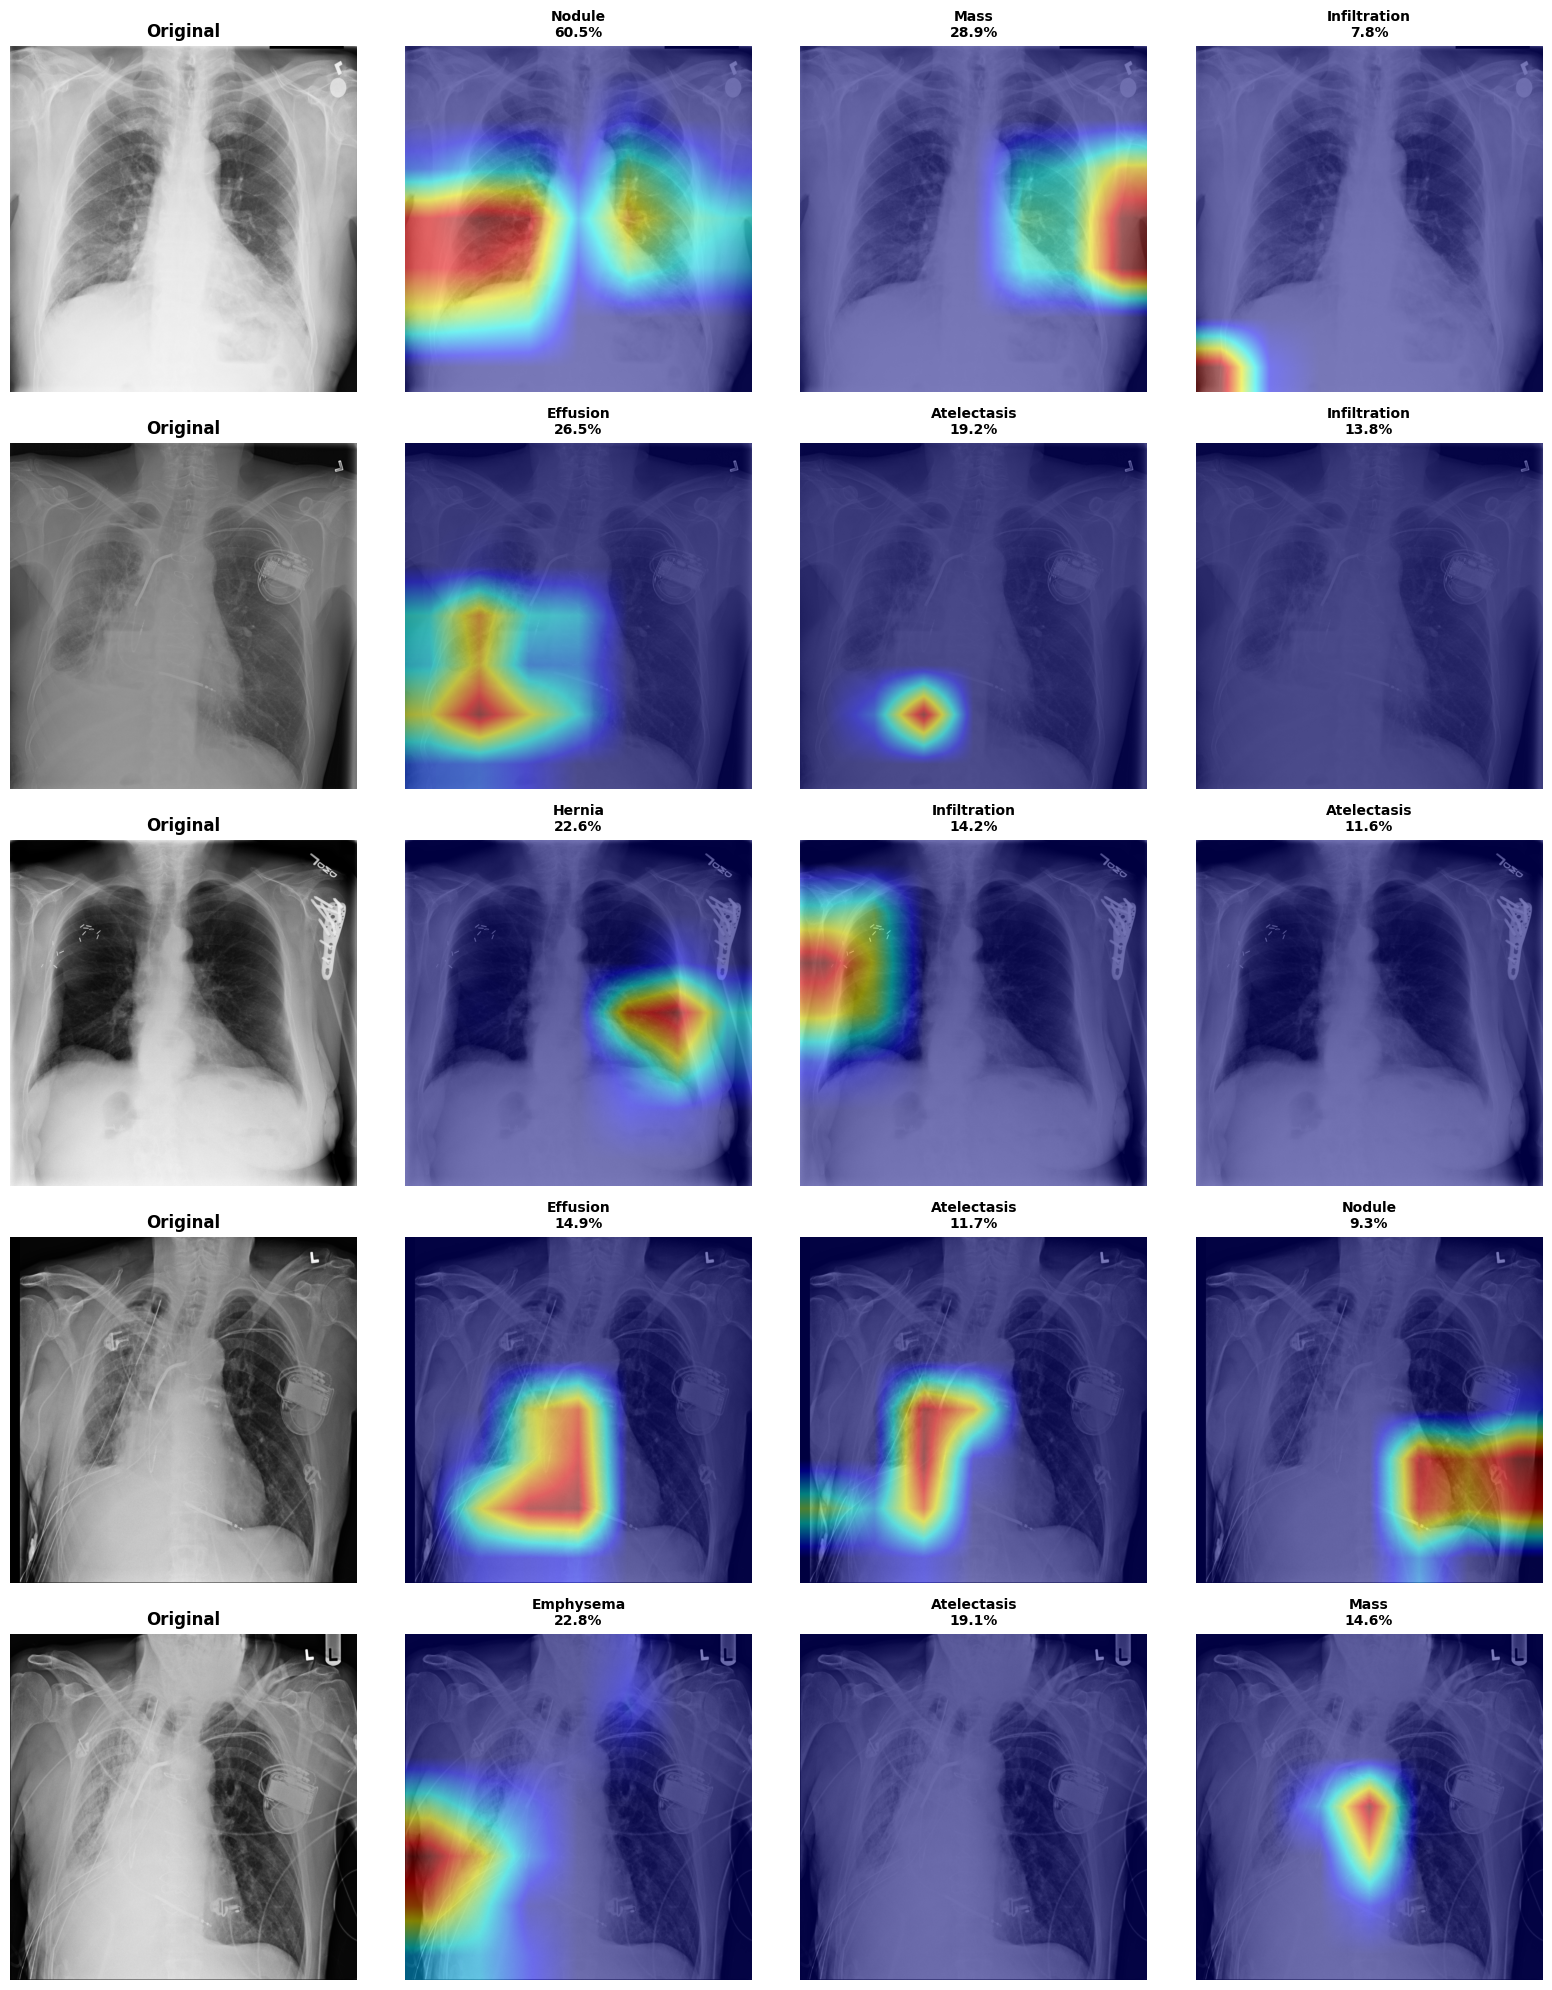

✅ Visualisations sauvegardées : results/gradcam_examples.png


In [7]:
# Tester sur 5 images aléatoires
print("🔄 Test sur 5 images aléatoires...")

fig, axes = plt.subplots(5, 4, figsize=(16, 20))

for i in range(5):
    # Image aléatoire
    img_path = random.choice(test_images)
    img = Image.open(img_path).convert('RGB')
    img_tensor = transform(img).unsqueeze(0).to(device)
    
    # Prédiction
    with torch.no_grad():
        output = model(img_tensor)
        probs = torch.sigmoid(output)[0]
    
    top_probs, top_indices = torch.topk(probs, 3)
    
    # Grad-CAM
    target_layer = get_target_layer(model, 'mobilenet')
    grad_cam = GradCAM(model, target_layer)
    
    # Afficher original
    axes[i, 0].imshow(img)
    axes[i, 0].set_title('Original', fontweight='bold')
    axes[i, 0].axis('off')
    
    # Grad-CAM pour top 3
    for j, (prob, idx) in enumerate(zip(top_probs, top_indices)):
        result, _ = grad_cam.visualize(img_tensor, img, class_idx=idx.item())
        axes[i, j+1].imshow(result)
        axes[i, j+1].set_title(
            f'{PATHOLOGIES[idx.item()]}\n{prob.item():.1%}',
            fontweight='bold', fontsize=10
        )
        axes[i, j+1].axis('off')

plt.tight_layout()
plt.savefig('../results/gradcam_examples.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ Visualisations sauvegardées : results/gradcam_examples.png")

---

## ✅ Conclusions

### 🎯 Grad-CAM nous permet de :

1. **Valider** que le modèle regarde les bonnes zones anatomiques
2. **Expliquer** les prédictions aux médecins
3. **Détecter** d'éventuels biais (ex: artefacts, texte)
4. **Améliorer la confiance** dans le système

### 🏥 Applications Cliniques

- **Aide au diagnostic** : Montre au radiologue où regarder
- **Enseignement médical** : Outil pédagogique
- **Validation** : Vérifie que l'IA n'utilise pas d'artefacts

---

**✅ Grad-CAM implémenté et validé avec succès !**